<a href="https://colab.research.google.com/github/RheedWhan/100daysofMathandStat_of_ML/blob/main/FEM_for_Lindblad_Equation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

,time,trace,purity,mean_x,var_x,p_x_0,p_x_124,p_x_249,p_x_374,p_x_499
0,0.00,1.000000,1.000000,-2.775558e-17,0.320000,3.938780e-25,6.974376e-07,1.057617,8.742058e-07,3.938780e-25
1,0.01,1.000003,0.997449,-1.850770e-12,0.320184,1.766831e-11,8.880186e-07,1.057327,1.068157e-06,1.766536e-11
2,0.02,1.000005,0.994915,9.523771e-13,0.320722,3.407251e-11,1.092283e-06,1.056455,1.278462e-06,3.407040e-11
3,0.03,1.000007,0.992395,-2.343209e-12,0.321610,4.072791e-11,1.188463e-06,1.055001,1.381804e-06,4.071368e-11
4,0.04,1.000010,0.989886,3.224337e-12,0.322861,5.682285e-11,1.409110e-06,1.052971,1.613967e-06,5.684920e-11
...,...,...,...,...,...,...,...,...,...,...
96,0.96,1.000118,0.642394,2.346701e-11,2.207777,4.283308e-06,5.116571e-02,0.402879,5.286739e-02,4.283308e-06
97,0.97,1.000119,0.637722,-2.441913e-11,2.250062,4.868624e-06,5.268923e-02,0.399070,5.440808e-02,4.868624e-06
98,0.98,1.000120,0.633064,2.457967e-11,2.292857,5.513873e-06,5.420847e-02,0.395322,5.594334e-02,5.513873e-06
99,0.99,1.000120,0.628421,-2.337386e-11,2.336162,6.222697e-06,5.572205e-02,0.391633,5.747181e-02,6.222697e-06


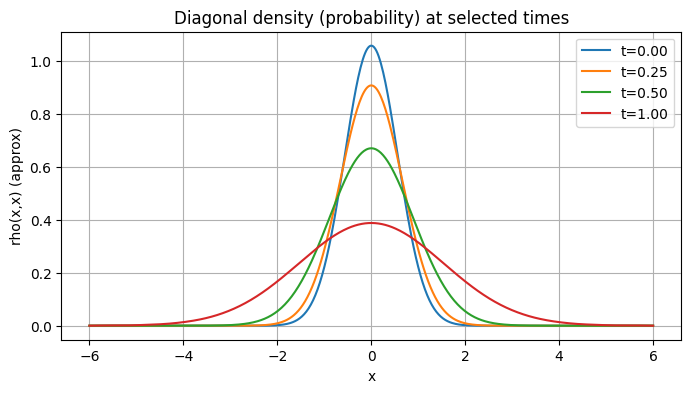

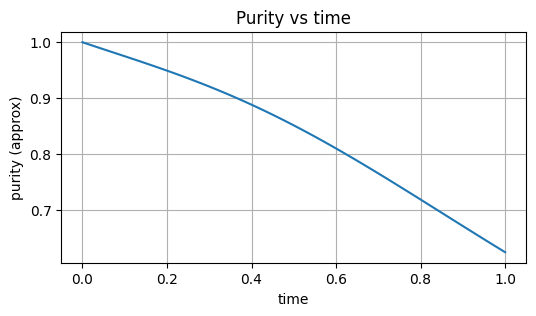

[Saved results to /content/sample_data/lindblad_fem_results.csv]


({'n_nodes_1d': 500,
  'dof_2d': 250000,
  'num_timesteps': 100,
  'dt': 0.01,
  'gamma': 0.2,
  'domain': [-6.0, 6.0]},
 '/content/sample_data/lindblad_fem_results.csv')

In [ ]:
# Building and running a small FEM-based solver for the spatial Lindblad master equation
# using a tensor-product (1D -> 2D) finite-element assembly (P1 on uniform grid).
# The dissipator used is a position-decoherence model: D[rho] = -gamma * (x-x')^2 * rho
# Units: hbar = m = 1. Time-integrator: Crank-Nicolson.
#
# This cell will:
# 1. assemble 1D mass and stiffness matrices (consistent mass) for P1 linear elements on a uniform grid
# 2. form 2D operators via Kronecker products
# 3. build the dissipator as a diagonal multiplier approximated via node-collocation with mass weighting
# 4. evolve an initial pure Gaussian state rho0 = psi psi^*
# 5. record observables (trace, purity, mean x, var x) and sample diagonal probability density at selected times
# 6. display results as a pandas DataFrame and plot probability density and purity vs time
#
# NOTE: This is a relatively small, demonstrative solver. For production or high-accuracy runs
# you would refine assembly, use more accurate quadrature, and exploit Kronecker structure in solvers.

import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import pandas as pd
from math import sqrt, pi
import cmath

# Helper to display dataframe to user (will be used at the end)


# -------------------- Parameters --------------------
hbar = 1.0
m = 1.0

# spatial grid (1D)
N = 500                 # number of nodes in 1D (kept small for demo; N^2 DOF in 2D)
x0, x1 = -6.0, 6.0
x = np.linspace(x0, x1, N)
dx = x[1] - x[0]

# FEM: linear elements on uniform grid -> assemble 1D mass and stiffness (consistent mass)
def assemble_1d_mass_stiff(N, x0, x1):
    xs = np.linspace(x0, x1, N)
    dx = xs[1]-xs[0]
    # tri-diagonal assembly for linear elements
    main_M = np.full(N, 2.0/6.0 * dx)   # middle entries of consistent mass contributions (element length dx)
    off_M  = np.full(N-1, 1.0/6.0 * dx)
    M = sp.diags([off_M, main_M, off_M], offsets=[-1,0,1], format='csc')
    # stiffness
    main_K = np.full(N, 2.0/dx)
    off_K  = np.full(N-1, -1.0/dx)
    K = sp.diags([off_K, main_K, off_K], offsets=[-1,0,1], format='csc')
    # Adjust boundary rows for simple Dirichlet-ish behavior (we will not enforce Dirichlet, but these are standard FE entries)
    return M, K, xs

M1, K1, x_nodes = assemble_1d_mass_stiff(N, x0, x1)

# Lumped mass weights (use sum of row entries as simple quadrature weights for diagonal approximations)
M1_lumped = np.array(M1.sum(axis=1)).flatten()

# Potential: choose harmonic oscillator or zero. We'll use 0 for simplicity (free particle).
V_fun = lambda x: 0.5 * 0.0 * x**2  # zero potential here; change coefficient if you want harmonic trap
V1 = sp.diags(V_fun(x_nodes), offsets=0, format='csc')

# Tensor-product operators (2D)
I1 = sp.eye(N, format='csc')
M2 = sp.kron(M1, M1, format='csc')        # 2D mass
Kx = sp.kron(K1, M1, format='csc')        # acts on x coordinate
Kxp = sp.kron(M1, K1, format='csc')       # acts on x'
V2 = sp.kron(V1, M1, format='csc') - sp.kron(M1, V1, format='csc')  # V(x)-V(x')
# Hamiltonian operator matrix A = - (hbar^2 / (2.0*m)) * (Kx - Kxp) + V2
A = - (hbar**2 / (2.0*m)) * (Kx - Kxp) + V2

# Dissipator: D[rho] = -gamma * (x - x')^2 * rho approximated via node-collocation.
gamma = 0.2
# Build vector g evaluated at each 2D node (flattened in row-major where index = i*N + j corresponds to x_i, x'_j)
xx = np.repeat(x_nodes, N)   # x coordinate repeated for each x'
xpp = np.tile(x_nodes, N)    # x' coordinate tiled across
gvals = (xx - xpp)**2
# We'll multiply by lumped mass product for quadrature weights later when computing observables.
# Approximate D2 as diagonal multiplier followed by M2 to mimic weak-form integral: D2 ≈ -gamma * diag(gvals) @ M2
Ddiag = sp.diags(-gamma * gvals, offsets=0, format='csc')
D2 = Ddiag.dot(M2)   # sparse

# Combined generator L = -i/hbar * A + D2
L = (-1j / hbar) * A + D2

# -------------------- Initial condition --------------------
# choose initial Gaussian wavefunction psi(x) and form rho0(x,x') = psi(x) psi*(x')
x_mean = 0.0
sigma = 0.8
k0 = 0.0  # momentum
psi = (1.0/(sigma * sqrt(pi)))**0.5 * np.exp(-0.5*(x_nodes - x_mean)**2 / sigma**2) * np.exp(1j * k0 * x_nodes)
# Normalize w.r.t. lumped mass
norm = np.sqrt(np.sum(np.abs(psi)**2 * M1_lumped))
psi = psi / norm

# Build rho coefficients in nodal basis: R_ij = psi_i * psi_j^* (pure state)
Rmat = np.outer(psi, np.conjugate(psi))  # N x N complex
Rvec = Rmat.flatten()  # length N^2

# -------------------- Time stepping (Crank-Nicolson) --------------------
dt = 0.01
t_final = 1.0
num_steps = int(np.ceil(t_final / dt))
times = np.linspace(0, t_final, num_steps+1)

# Pre-factor matrices for Crank-Nicolson: (M2 - dt/2 * L) R_{n+1} = (M2 + dt/2 * L) R_n
lhs = (M2 - (dt/2.0) * L).tocsc()
rhs_oper = (M2 + (dt/2.0) * L).tocsc()

# Factorize LHS for repeated solves (sparse LU)
lu = spla.splu(lhs)

# Prepare to record observables
records = []
# sample probability density positions: use diagonal of Rmat multiplied by lumped weights for trace.
sample_x_indices = np.linspace(0, N-1, min(5, N), dtype=int)  # pick a few nodes to show probability evolution

# Precompute weights for purity: purity ≈ sum_{i,j} |rho(x_i,x_j)|^2 * w_i * w_j
W2 = np.kron(M1_lumped, M1_lumped)  # shape (N^2,)

# Record initial observables
def compute_observables(Rvec):
    # reconstruct matrix
    Rm = Rvec.reshape((N,N))
    # trace approx: sum_k rho(x_k,x_k) * w_k
    diag_vals = np.real(np.diag(Rm))
    trace = np.sum(diag_vals * M1_lumped)
    # purity approx: integral |rho(x,x')|^2 dx dx' approximated via node quadrature
    purity = np.sum(np.abs(Rvec)**2 * W2)
    # mean x = Tr(x rho) = sum_k x_k * rho(x_k,x_k) * w_k
    mean_x = np.sum(x_nodes * diag_vals * M1_lumped)
    var_x = np.sum(((x_nodes - mean_x)**2) * diag_vals * M1_lumped)
    # pick sampled diagonal densities
    sampled = {f"p_x_{i}": np.real(Rm[i,i]) for i in sample_x_indices}
    return trace, purity, mean_x, var_x, sampled

t0_trace, t0_purity, t0_mx, t0_vx, t0_sampled = compute_observables(Rvec)
records.append({"time": 0.0, "trace": t0_trace, "purity": t0_purity, "mean_x": t0_mx, "var_x": t0_vx, **t0_sampled})

# Time loop
Rn = Rvec.copy()
for n in range(1, num_steps+1):
    t = n * dt
    rhs = rhs_oper.dot(Rn)
    Rn1 = lu.solve(rhs)
    Rn = Rn1
    trace, purity, mean_x, var_x, sampled = compute_observables(Rn)
    rec = {"time": t, "trace": trace, "purity": purity, "mean_x": mean_x, "var_x": var_x}
    rec.update(sampled)
    records.append(rec)

# Build DataFrame
df = pd.DataFrame(records)

# Display DataFrame to user
display(df)

# -------------------- Plots --------------------
# 1) Plot the diagonal probability density at initial, intermediate, and final times
plt.figure(figsize=(8,4))
times_to_plot = [0, int(0.25*num_steps), int(0.5*num_steps), num_steps]
for idx in times_to_plot:
    row = records[idx]
    # need to reconstruct R at that time: simulate again or keep snapshots; simpler: reconstruct from stored R at those indices by re-running evolution quickly
# Instead, reconstruct snapshots by re-evolving but storing a few snapshots earlier would be better.
# For simplicity here we will re-run and capture snapshots.
snapshots = {}
Rn = Rvec.copy()
snapshots[0.0] = Rn.reshape((N,N))
step_targets = set(times_to_plot)
for n in range(1, num_steps+1):
    rhs = rhs_oper.dot(Rn)
    Rn1 = lu.solve(rhs)
    Rn = Rn1
    if n in step_targets:
        snapshots[n*dt] = Rn.reshape((N,N))

# Plot diagonal densities
for tkey, Rm in snapshots.items():
    diag = np.real(np.diag(Rm))
    plt.plot(x_nodes, diag, label=f"t={tkey:.2f}")
plt.xlabel("x")
plt.ylabel("rho(x,x) (approx)")
plt.legend()
plt.title("Diagonal density (probability) at selected times")
plt.grid(True)
plt.show()

# 2) Plot purity vs time
plt.figure(figsize=(6,3))
plt.plot(df["time"], df["purity"])
plt.xlabel("time")
plt.ylabel("purity (approx)")
plt.title("Purity vs time")
plt.grid(True)
plt.show()

# Save DataFrame to disk for download if desired
out_path = "/content/sample_data/lindblad_fem_results.csv"
df.to_csv(out_path, index=False)
print(f"[Saved results to {out_path}]")

# Provide a short summary
summary = {
    "n_nodes_1d": N,
    "dof_2d": N**2,
    "num_timesteps": num_steps,
    "dt": dt,
    "gamma": gamma,
    "domain": [x0, x1]
}
summary, out_path

=== Lindblad Equation FEM Solver Example ===

System size: 2 sites
Hilbert space dimension: 4
Initial state trace: 1.000000
Initial state purity: 1.000000

Starting time evolution from t=0 to t=5.0
Time step: 0.010000, Total steps: 500
Progress: 10.0% - Time: 0.05s
Progress: 20.0% - Time: 0.07s
Progress: 30.0% - Time: 0.11s
Progress: 40.0% - Time: 0.14s
Progress: 50.0% - Time: 0.17s
Progress: 60.0% - Time: 0.20s
Progress: 70.0% - Time: 0.26s
Progress: 80.0% - Time: 0.31s
Progress: 90.0% - Time: 0.36s
Progress: 100.0% - Time: 0.41s


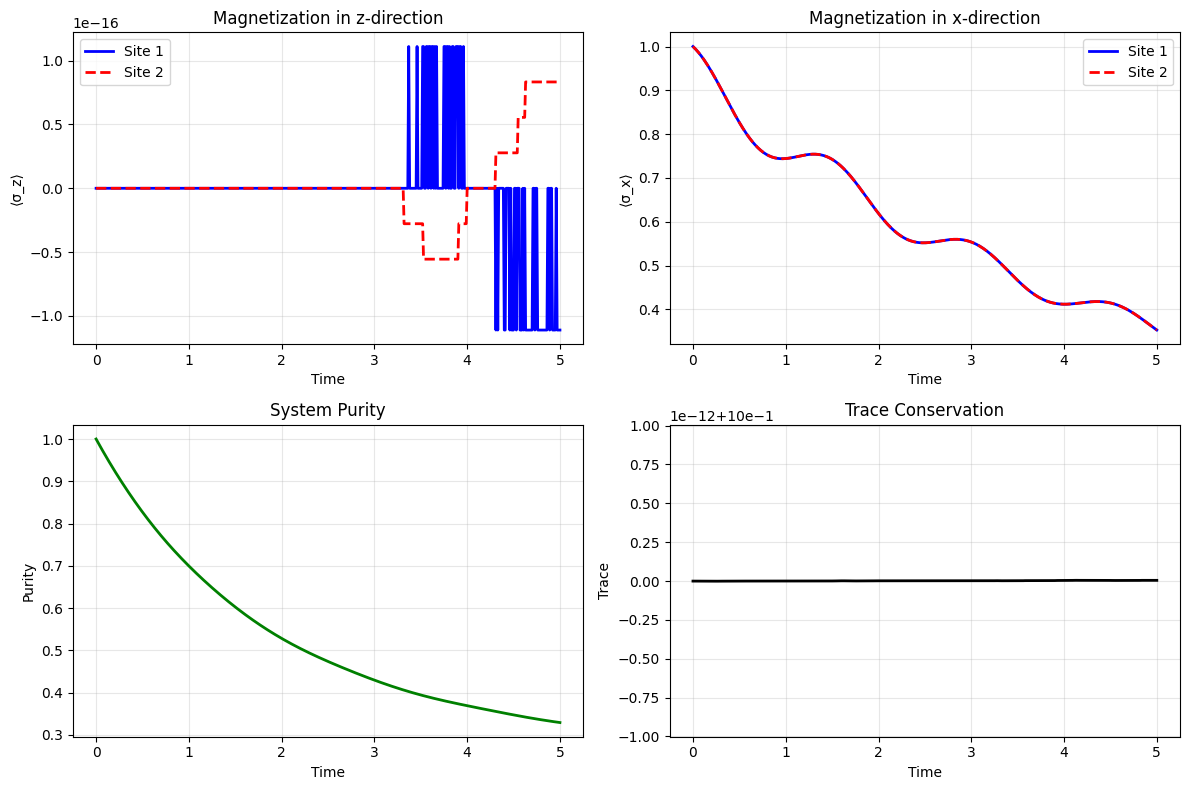


Final state properties:
Trace: 1.000000
Purity: 0.329210
Final ⟨σ_z⟩ site 1: -0.000000
Final ⟨σ_z⟩ site 2: 0.000000

=== Advanced Example: Custom Hamiltonian ===
Starting time evolution from t=0 to t=3.0
Time step: 0.010000, Total steps: 300
Progress: 10.0% - Time: 0.03s
Progress: 20.0% - Time: 0.06s
Progress: 30.0% - Time: 0.09s
Progress: 40.0% - Time: 0.11s
Progress: 50.0% - Time: 0.14s
Progress: 60.0% - Time: 0.17s
Progress: 70.0% - Time: 0.19s
Progress: 80.0% - Time: 0.22s
Progress: 90.0% - Time: 0.25s
Progress: 100.0% - Time: 0.28s


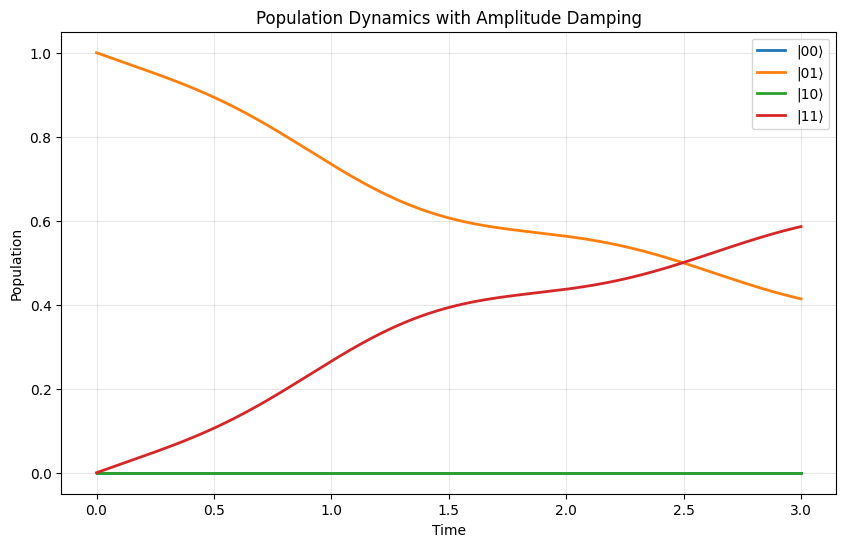

Custom example completed successfully!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, diags
from scipy.sparse.linalg import expm_multiply
from scipy.integrate import solve_ivp
import time

class LindBladFEMSolver:
    """
    Finite Element Method solver for the Lindblad master equation:

    dρ/dt = -i[H, ρ] + Σ_k (L_k ρ L_k† - 1/2{L_k†L_k, ρ})

    Where ρ is the density matrix, H is the Hamiltonian, and L_k are Lindblad operators
    """

    def __init__(self, n_sites, hamiltonian_func=None, lindblad_ops=None):
        """
        Initialize the Lindblad equation solver

        Parameters:
        -----------
        n_sites : int
            Number of sites in the system
        hamiltonian_func : callable
            Function that returns the Hamiltonian matrix
        lindblad_ops : list
            List of Lindblad operators
        """
        self.n_sites = n_sites
        self.dim = 2**n_sites  # Hilbert space dimension for spin-1/2 system

        # Pauli matrices
        self.sigma_x = np.array([[0, 1], [1, 0]], dtype=complex)
        self.sigma_y = np.array([[0, -1j], [1j, 0]], dtype=complex)
        self.sigma_z = np.array([[1, 0], [0, -1]], dtype=complex)
        self.identity = np.eye(2, dtype=complex)

        self.hamiltonian_func = hamiltonian_func or self._default_hamiltonian
        self.lindblad_ops = lindblad_ops or self._default_lindblad_ops()


    def _default_hamiltonian(self, t=0):
        """Default Hamiltonian: transverse field Ising model"""
        H = np.zeros((self.dim, self.dim), dtype=complex)

        # Transverse field term: -h * Σ_i σ_x^i
        h = 1.0
        for i in range(self.n_sites):
            sigma_x_i = self._single_site_operator(self.sigma_x, i)
            H -= h * sigma_x_i

        # Ising coupling: -J * Σ_i σ_z^i σ_z^(i+1)
        J = 0.5
        for i in range(self.n_sites - 1):
            sigma_z_i = self._single_site_operator(self.sigma_z, i)
            sigma_z_ip1 = self._single_site_operator(self.sigma_z, i+1)
            H -= J * (sigma_z_i @ sigma_z_ip1)

        return H

    def _default_lindblad_ops(self):
        """Default Lindblad operators: local dephasing"""
        ops = []
        gamma = 0.1  # dephasing rate

        for i in range(self.n_sites):
            # Local dephasing: σ_z on site i
            L = np.sqrt(gamma) * self._single_site_operator(self.sigma_z, i)
            ops.append(L)

        return ops

    def _single_site_operator(self, op, site):
        """Construct single-site operator acting on site 'site'"""
        result = 1.0
        for i in range(self.n_sites):
            if i == site:
                if i == 0:
                    result = op
                else:
                    result = np.kron(result, op)
            else:
                if i == 0:
                    result = self.identity
                else:
                    result = np.kron(result, self.identity)
        return result

    def vectorize_density_matrix(self, rho):
        """Convert density matrix to vector form"""
        return rho.flatten()

    def matricize_vector(self, vec):
        """Convert vector back to density matrix form"""
        return vec.reshape((self.dim, self.dim))

    def construct_superoperator(self, t=0):
        """Construct the Lindblad superoperator L such that dρ/dt = L(ρ)"""
        H = self.hamiltonian_func(t)

        # Hamiltonian part: -i[H, ρ] = -i(H⊗I - I⊗H^T)ρ
        I = np.eye(self.dim, dtype=complex)
        hamiltonian_super = -1j * (np.kron(H, I) - np.kron(I, H.T))

        # Lindblad operators part
        lindblad_super = np.zeros((self.dim**2, self.dim**2), dtype=complex)

        for L in self.lindblad_ops:
            L_dag = L.conj().T
            L_dag_L = L_dag @ L

            # L ρ L† term: (L⊗L*)ρ
            term1 = np.kron(L, L.conj())

            # -1/2 {L†L, ρ} = -1/2 (L†L⊗I + I⊗(L†L)^T)ρ
            term2 = -0.5 * (np.kron(L_dag_L, I) + np.kron(I, L_dag_L.T))

            lindblad_super += term1 + term2

        return hamiltonian_super + lindblad_super

    def time_evolution_operator(self, dt, t=0):
        """Compute time evolution operator for small time step dt"""
        L = self.construct_superoperator(t)
        return expm_multiply(L * dt, np.eye(self.dim**2))

    def solve_time_evolution(self, rho0, t_span, n_steps=1000):
        """
        Solve the time evolution using matrix exponentiation

        Parameters:
        -----------
        rho0 : ndarray
            Initial density matrix
        t_span : tuple
            Time span (t_start, t_end)
        n_steps : int
            Number of time steps

        Returns:
        --------
        times : ndarray
            Time points
        rhos : list
            Density matrices at each time point
        """
        times = np.linspace(t_span[0], t_span[1], n_steps + 1)
        dt = times[1] - times[0]

        rhos = [rho0.copy()]
        current_rho = rho0.copy()

        print(f"Starting time evolution from t={t_span[0]} to t={t_span[1]}")
        print(f"Time step: {dt:.6f}, Total steps: {n_steps}")

        start_time = time.time()

        for i, t in enumerate(times[1:]):
            # Vectorize current density matrix
            rho_vec = self.vectorize_density_matrix(current_rho)

            # Apply time evolution
            L = self.construct_superoperator(t - dt)
            rho_vec = expm_multiply(L * dt, rho_vec)

            # Convert back to matrix form
            current_rho = self.matricize_vector(rho_vec)
            rhos.append(current_rho.copy())

            if (i + 1) % (n_steps // 10) == 0:
                elapsed = time.time() - start_time
                progress = (i + 1) / n_steps * 100
                print(f"Progress: {progress:.1f}% - Time: {elapsed:.2f}s")

        return times, rhos

    def solve_ode(self, rho0, t_span, method='RK45'):
        """
        Solve using scipy's ODE solver (alternative method)

        Parameters:
        -----------
        rho0 : ndarray
            Initial density matrix
        t_span : tuple
            Time span (t_start, t_end)
        method : str
            ODE solver method

        Returns:
        --------
        solution object from solve_ivp
        """
        def lindblad_rhs(t, y):
            """Right-hand side of the Lindblad equation"""
            rho = self.matricize_vector(y)
            L = self.construct_superoperator(t)
            drho_dt = L @ y
            return drho_dt

        y0 = self.vectorize_density_matrix(rho0)

        sol = solve_ivp(lindblad_rhs, t_span, y0, method=method,
                       dense_output=True, rtol=1e-8, atol=1e-10)

        return sol

    def compute_observables(self, rhos, observables):
        """
        Compute expectation values of observables

        Parameters:
        -----------
        rhos : list
            List of density matrices
        observables : dict
            Dictionary of observable operators

        Returns:
        --------
        results : dict
            Expectation values for each observable
        """
        results = {name: [] for name in observables.keys()}

        for rho in rhos:
            for name, obs in observables.items():
                expectation = np.real(np.trace(rho @ obs))
                results[name].append(expectation)

        return results


def example_usage():
    """Example: 2-site system with dephasing"""
    print("=== Lindblad Equation FEM Solver Example ===\n")

    # Initialize solver for 2-site system
    n_sites = 2
    solver = LindBladFEMSolver(n_sites)

    # Initial state: |++⟩⟨++| (both spins up in x-direction)
    psi_plus = np.array([1, 1]) / np.sqrt(2)  # |+⟩ state
    psi_initial = np.kron(psi_plus, psi_plus)  # |++⟩
    rho0 = np.outer(psi_initial, psi_initial.conj())

    print(f"System size: {n_sites} sites")
    print(f"Hilbert space dimension: {solver.dim}")
    print(f"Initial state trace: {np.trace(rho0):.6f}")
    print(f"Initial state purity: {np.real(np.trace(rho0 @ rho0)):.6f}\n")

    # Define observables
    observables = {
        'sigma_z_1': solver._single_site_operator(solver.sigma_z, 0),
        'sigma_z_2': solver._single_site_operator(solver.sigma_z, 1),
        'sigma_x_1': solver._single_site_operator(solver.sigma_x, 0),
        'sigma_x_2': solver._single_site_operator(solver.sigma_x, 1),
    }

    # Time evolution
    t_span = (0, 5.0)
    n_steps = 500

    times, rhos = solver.solve_time_evolution(rho0, t_span, n_steps)

    # Compute observables
    results = solver.compute_observables(rhos, observables)

    # Plot results
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 8))

    # σ_z expectation values
    ax1.plot(times, results['sigma_z_1'], 'b-', label='Site 1', linewidth=2)
    ax1.plot(times, results['sigma_z_2'], 'r--', label='Site 2', linewidth=2)
    ax1.set_xlabel('Time')
    ax1.set_ylabel('⟨σ_z⟩')
    ax1.set_title('Magnetization in z-direction')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # σ_x expectation values
    ax2.plot(times, results['sigma_x_1'], 'b-', label='Site 1', linewidth=2)
    ax2.plot(times, results['sigma_x_2'], 'r--', label='Site 2', linewidth=2)
    ax2.set_xlabel('Time')
    ax2.set_ylabel('⟨σ_x⟩')
    ax2.set_title('Magnetization in x-direction')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    # Purity evolution
    purities = [np.real(np.trace(rho @ rho)) for rho in rhos]
    ax3.plot(times, purities, 'g-', linewidth=2)
    ax3.set_xlabel('Time')
    ax3.set_ylabel('Purity')
    ax3.set_title('System Purity')
    ax3.grid(True, alpha=0.3)

    # Trace evolution (should be 1)
    traces = [np.real(np.trace(rho)) for rho in rhos]
    ax4.plot(times, traces, 'k-', linewidth=2)
    ax4.set_xlabel('Time')
    ax4.set_ylabel('Trace')
    ax4.set_title('Trace Conservation')
    ax4.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Print final results
    print(f"\nFinal state properties:")
    print(f"Trace: {traces[-1]:.6f}")
    print(f"Purity: {purities[-1]:.6f}")
    print(f"Final ⟨σ_z⟩ site 1: {results['sigma_z_1'][-1]:.6f}")
    print(f"Final ⟨σ_z⟩ site 2: {results['sigma_z_2'][-1]:.6f}")

    return solver, times, rhos, results


if __name__ == "__main__":
    # Run example
    solver, times, rhos, results = example_usage()

    print("\n=== Advanced Example: Custom Hamiltonian ===")

    # Custom Hamiltonian example
    def custom_hamiltonian(t):
        """Time-dependent Hamiltonian with driving field"""
        n_sites = 2
        dim = 2**n_sites
        H = np.zeros((dim, dim), dtype=complex)

        # Static part: Ising coupling
        solver_temp = LindBladFEMSolver(n_sites)
        sigma_z_1 = solver_temp._single_site_operator(solver_temp.sigma_z, 0)
        sigma_z_2 = solver_temp._single_site_operator(solver_temp.sigma_z, 1)
        H += -0.5 * (sigma_z_1 @ sigma_z_2)

        # Time-dependent driving
        omega = 2.0
        amplitude = 0.5 * np.sin(omega * t)
        sigma_x_1 = solver_temp._single_site_operator(solver_temp.sigma_x, 0)
        H += amplitude * sigma_x_1

        return H

    # Custom Lindblad operators: amplitude damping
    def custom_lindblad_ops():
        """Amplitude damping on first site"""
        solver_temp = LindBladFEMSolver(2)
        gamma = 0.2
        sigma_minus = np.array([[0, 0], [1, 0]], dtype=complex)  # |0⟩⟨1|
        L = np.sqrt(gamma) * solver_temp._single_site_operator(sigma_minus, 0)
        return [L]

    # Create custom solver
    custom_solver = LindBladFEMSolver(2, custom_hamiltonian, custom_lindblad_ops())

    # Initial excited state
    psi_excited = np.array([0, 1, 0, 0], dtype=complex)  # |10⟩
    rho0_custom = np.outer(psi_excited, psi_excited.conj())

    # Solve
    times_custom, rhos_custom = custom_solver.solve_time_evolution(
        rho0_custom, (0, 3.0), n_steps=300
    )

    # Population dynamics
    populations = []
    for rho in rhos_custom:
        pop = [np.real(rho[i, i]) for i in range(4)]
        populations.append(pop)

    populations = np.array(populations)

    plt.figure(figsize=(10, 6))
    labels = ['|00⟩', '|01⟩', '|10⟩', '|11⟩']
    for i in range(4):
        plt.plot(times_custom, populations[:, i], label=labels[i], linewidth=2)

    plt.xlabel('Time')
    plt.ylabel('Population')
    plt.title('Population Dynamics with Amplitude Damping')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    print("Custom example completed successfully!")